In [1]:
import sys
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

sys.path.append(str(Path().resolve().parent/"src"))
from features import add_geometry_features
from evaluation import add_results, plot_pred_vs_true

results = {}

In [2]:
# Load the CSV data into dataframe
CSV_PATH = Path().resolve().parent/"data"/"processed"/"airfrans_coefficients.csv"
df = pd.read_csv(CSV_PATH)

# Add the geometry features
df = add_geometry_features(df)

# Split on full set
train_df = df.loc[df["split_full"]=="train"]
test_df = df.loc[df["split_full"]=="test"]


# RandomForestRegressor



--- Cl (coefficient of Lift) ---
MAE: 0.05160770561550942
RMSE: 0.07249646393435646
R^2: 0.9843353612348823
--- Cd (coefficient of Drag) ---
MAE: 0.0006933620991336455
RMSE: 0.0011229560895261513
R^2: 0.9435410550221563


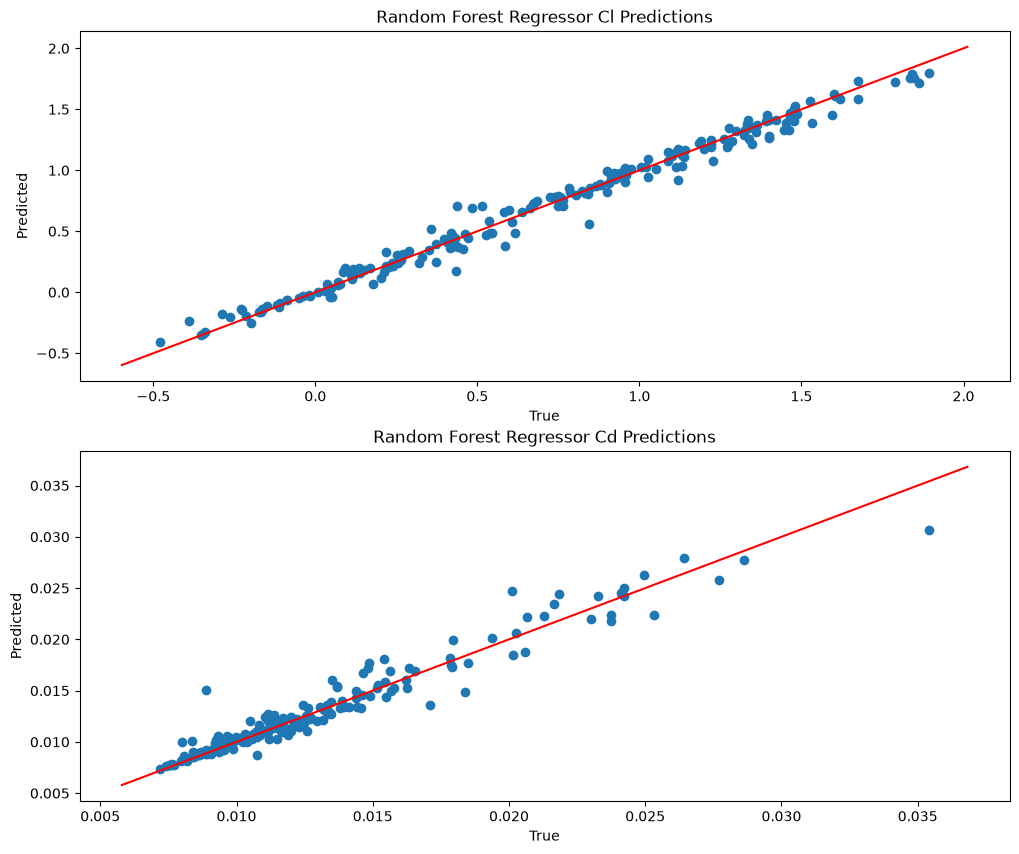

In [3]:
FEATURES = ["angleOfAttack","Re","max_camber","camber_pos","thickness","reflex"]

x_train = train_df[FEATURES]
x_test = test_df[FEATURES]
y_train = train_df[["cl","cd"]]
y_test = test_df[["cl","cd"]]

rf_cl = RandomForestRegressor(random_state=0)
rf_cl.fit(x_train, y_train["cl"])
cl_pred = rf_cl.predict(x_test)

rf_cd = RandomForestRegressor(random_state=0)
rf_cd.fit(x_train, y_train["cd"])
cd_pred = rf_cd.predict(x_test)

results = add_results(results, "random_forest_regressor",
                      cl_true=y_test["cl"], cl_pred=cl_pred,
                      cd_true=y_test["cd"], cd_pred=cd_pred)

fig, ax = plt.subplots(2, figsize=(12,10))
plot_pred_vs_true(ax[0], y_test["cl"], cl_pred, "Random Forest Regressor Cl Predictions")
plot_pred_vs_true(ax[1],y_test["cd"],cd_pred,"Random Forest Regressor Cd Predictions")

In [4]:
# View the feature importances for both models
rf_cl_importances = pd.Series(rf_cl.feature_importances_, index=rf_cl.feature_names_in_)
rf_cd_importances = pd.Series(rf_cd.feature_importances_, index=rf_cd.feature_names_in_)

print(f"--- Cl Feature Importances ---\n{rf_cl_importances}")
print(f"\n--- Cd Feature Importances ---\n{rf_cd_importances}")

--- Cl Feature Importances ---
angleOfAttack    0.907486
Re               0.001999
max_camber       0.059996
camber_pos       0.025250
thickness        0.004946
reflex           0.000322
dtype: float64

--- Cd Feature Importances ---
angleOfAttack    0.823026
Re               0.038337
max_camber       0.031669
camber_pos       0.021236
thickness        0.079962
reflex           0.005770
dtype: float64


The Importances look as expected with the `angleOfAttack` having the largest importance, however each other models is also taken into account. Though it is worth noting the differences between them; For the coefficient of Lift, the angle is the most important followed by the max_camber and the camber_pos with the thickness and RE having little effect on the outcome. Drag however has less of a reliance on AoA, followed by the thickeness and then the RE. Which I can understand as the larger drag comes from having a larger object moving through which is thickness.

---

# Gradient Boosting


--- Cl (coefficient of Lift) ---
MAE: 0.04136770443634154
RMSE: 0.057393316362481614
R^2: 0.9901823085990875
--- Cd (coefficient of Drag) ---
MAE: 0.0005479599918404763
RMSE: 0.0008812365716687876
R^2: 0.9652309972949504


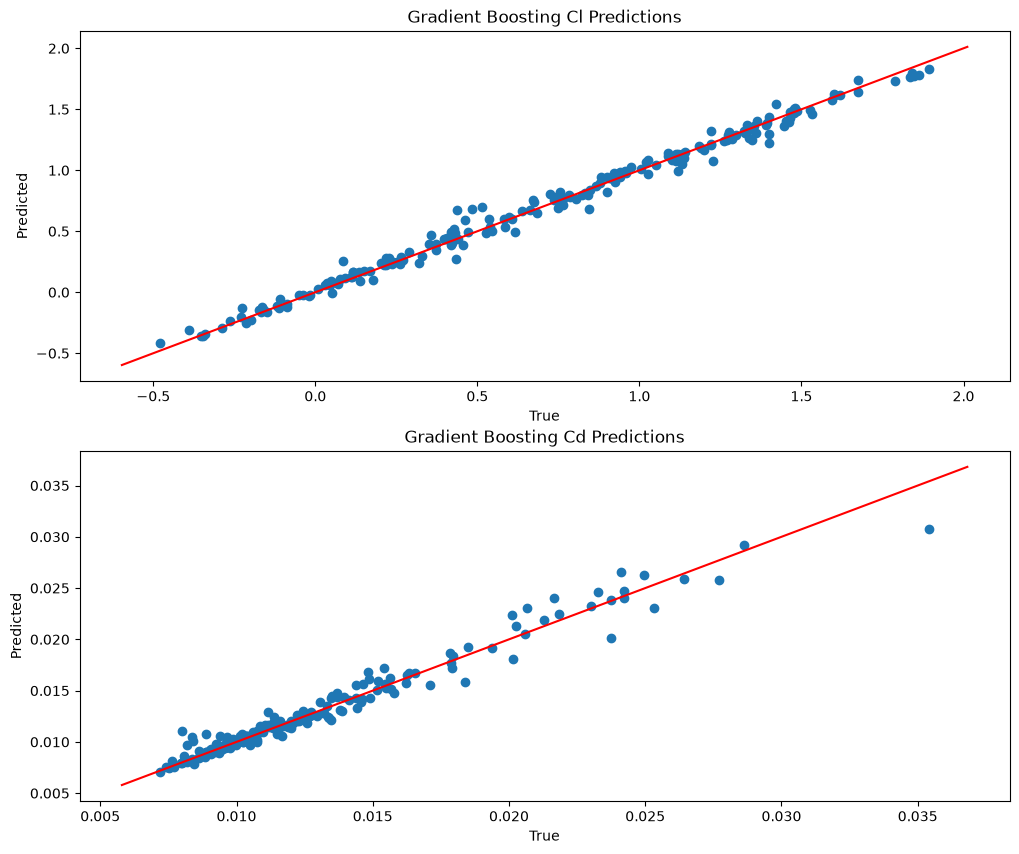

In [5]:
hgb_cl = HistGradientBoostingRegressor(random_state=0)
hgb_cl.fit(x_train,y_train["cl"])
cl_pred = hgb_cl.predict(x_test)

hgb_cd = HistGradientBoostingRegressor(random_state=0)
hgb_cd.fit(x_train,y_train["cd"])
cd_pred = hgb_cd.predict(x_test)

results = add_results(results, "hist_gradient_boosing",
                      cl_true=y_test["cl"], cl_pred=cl_pred,
                      cd_true=y_test["cd"], cd_pred=cd_pred)

fig, ax = plt.subplots(2, figsize=(12,10))
plot_pred_vs_true(ax[0], y_test["cl"], cl_pred, "Gradient Boosting Cl Predictions")
plot_pred_vs_true(ax[1],y_test["cd"],cd_pred,"Gradient Boosting Cd Predictions")

In [6]:
print(pd.DataFrame(results))

         random_forest_regressor  hist_gradient_boosing
cl_mae                  0.051608               0.041368
cl_rmse                 0.072496               0.057393
cl_r2                   0.984335               0.990182
cd_mae                  0.000693               0.000548
cd_rmse                 0.001123               0.000881
cd_r2                   0.943541               0.965231


In [7]:
# Run a cross validation score for each models
rf_cl_scores = cross_val_score(rf_cl, x_train, y_train["cl"],cv=5,scoring="r2")
hgb_cl_scores = cross_val_score(hgb_cl, x_train, y_train["cl"], cv=5, scoring="r2")

rf_cd_scores = cross_val_score(rf_cd, x_train, y_train["cd"],cv=5,scoring="r2")
hgb_cd_scores = cross_val_score(hgb_cd, x_train, y_train["cd"], cv=5, scoring="r2")

print("\n--- Cl cross val scores ---")
print("rf: ",rf_cl_scores.mean(), rf_cl_scores.std())
print("hgb: ",hgb_cl_scores.mean(), hgb_cl_scores.std())

print("\n--- Cd cross val scores ---")
print("rf: ",rf_cd_scores.mean(), rf_cd_scores.std())
print("hgb: ",hgb_cd_scores.mean(), hgb_cd_scores.std())




--- Cl cross val scores ---
rf:  0.9847185825502434 0.001548154828059026
hgb:  0.9917243576152792 0.0010252612302956356

--- Cd cross val scores ---
rf:  0.8404432460843708 0.0926087509269096
hgb:  0.8663532402516629 0.10902402780440038


From the cross validation scores, CL results in a higher mean, and a lower std deviation meaning a better model, however the same cannot be said for CD, it results in a higher mean yes, but the std deviation is higher but also that the difference between the cross val r2 scores and the test-set r2 scores is about 0.1 lower.

In [8]:
# exploring the reason for the large cd r2 mean discrepency

print("rf_cd scores: ",rf_cd_scores)
print("hgb_cd scores: ",hgb_cd_scores)

# Looks to be a clear drop in accuracy on the second block that then slowly recovers.

rf_cd scores:  [0.90054116 0.67407319 0.89443134 0.80613023 0.92704031]
hgb_cd scores:  [0.95332089 0.67475769 0.93646854 0.81415722 0.95306187]


In [9]:
# attempting again with KFold 
cv = KFold(n_splits=5, shuffle=True, random_state=0)
rf_cd_scores = cross_val_score(rf_cd, x_train, y_train["cd"],cv=cv,scoring="r2")
hgb_cd_scores = cross_val_score(hgb_cd, x_train, y_train["cd"], cv=cv, scoring="r2")
print("\n--- Cd cross val scores ---")
print("rf: ",rf_cd_scores.mean(), rf_cd_scores.std())
print("hgb: ",hgb_cd_scores.mean(), hgb_cd_scores.std())

print("rf_cd scores: ",rf_cd_scores)
print("hgb_cd scores: ",hgb_cd_scores)


--- Cd cross val scores ---
rf:  0.844331834175198 0.09346735259556824
hgb:  0.8685370771417211 0.09742161305948778
rf_cd scores:  [0.86278529 0.94521366 0.68283273 0.92105637 0.80977111]
hgb_cd scores:  [0.94059457 0.95067016 0.69866931 0.93355426 0.81919709]


In [11]:
# using the cross-val-predict and stoor those
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(hgb_cd, x_train, y_train["cd"],cv=cv)
train_df["relative_error"] = abs(oof-y_train["cd"])/y_train["cd"]
train_df.sort_values(by="relative_error", ascending=False)

,name,inletVelocity,Re,angleOfAttack,M,L,P,Q,XX,cl,...,cd_p_cal,split_full,split_scarce,split_reynolds,split_aoa,max_camber,camber_pos,thickness,reflex,relative_error
607,airFoil2D_SST_35.32_-4.403_1.396_0.0_5.379,35.320,2.264103e+06,-4.403,1.396,NaN,0.000,NaN,5.379,-0.480263,...,0.002171,train,NaN,test,test,0.013960,0.0000,0.05379,0,0.845747
171,airFoil2D_SST_50.077_-4.416_2.834_4.029_1.0_5.156,50.077,3.210064e+06,-4.416,NaN,2.834,4.029,True,5.156,-0.282945,...,0.042707,train,train,train,test,0.029554,0.2010,0.05156,1,0.768396
554,airFoil2D_SST_37.191_-4.384_1.742_3.249_0.0_5.697,37.191,2.384038e+06,-4.384,NaN,1.742,3.249,False,5.697,-0.330303,...,0.030645,train,NaN,test,test,0.016592,0.1620,0.05697,0,0.698006
389,airFoil2D_SST_92.774_-4.444_3.376_3.813_5.69,92.774,5.947051e+06,-4.444,3.376,NaN,3.813,NaN,5.690,-0.119076,...,0.001793,train,NaN,test,test,0.033760,0.3813,0.05690,0,0.673783
200,airFoil2D_SST_44.846_-0.985_5.53_0.0_5.101,44.846,2.874744e+06,-0.985,5.530,NaN,0.000,NaN,5.101,-0.107654,...,0.000609,train,NaN,test,train,0.055300,0.0000,0.05101,0,0.646853
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
570,airFoil2D_SST_74.577_10.798_1.552_6.403_0.0_9.246,74.577,4.780577e+06,10.798,NaN,1.552,6.403,False,9.246,1.292828,...,0.008161,train,NaN,train,train,0.018875,0.3200,0.09246,0,0.000342
59,airFoil2D_SST_75.03_3.282_5.553_1.947_9.749,75.030,4.809615e+06,3.282,5.553,NaN,1.947,NaN,9.749,0.900631,...,0.003073,train,train,train,train,0.055530,0.1947,0.09749,0,0.000234
740,airFoil2D_SST_78.333_-1.115_5.593_4.208_16.049,78.333,5.021346e+06,-1.115,5.593,NaN,4.208,NaN,16.049,0.461235,...,0.002938,train,NaN,test,train,0.055930,0.4208,0.16049,0,0.000148
615,airFoil2D_SST_77.117_6.408_1.603_6.213_1.0_9.714,77.117,4.943397e+06,6.408,NaN,1.603,6.213,True,9.714,0.853870,...,0.003290,train,NaN,train,train,0.019360,0.3110,0.09714,1,0.000138


After calculating the relative errors from the cross-validation and looking at the largest errors (worst = 0.8457), some of the results I see is the thickeness of the worst 5 entries are all ~0.05. All the top 9 errors are all a negative AoA, with most being ~-4/-4.5 which is at the lower extreme of the dataset as a whole

Looking further into this, the training data for large negative AoA (below -3.5 degress) airfoils and thin (Thickness below 7%)airfoils is relatively low (12 airfoils), and within those there is a large discrepancy between the Cd values with 10 low-drag airfoils and 2 high-drag airfoils; (min being 0.0078, max being 0.0459) this large discrepancy in combination with few examples explains why both models (random forest and gradient boosing) are perfoming worse at predicting this subset of airfoils. This is Likely flow separation: the two high-drag cases get 88-93% of their drag from pressure, against ~31% typically (Not yet confirmed by inspecting the flow). where if the airfoil does separate the drag drastically increases (two high-drag airfoils) whereas if it doesnt, it leads to the low-drag situation (the other 10 airfoils). Its also worth noting that RANS is known to be least reliable when the flow separates.

As a result of this, the test-set Cd R^2 score of 0.965 is likely optimistic; with models being least reliable for thin airfoils at negative angles.

In [12]:
# Store the results as csv
RESULTS_PATH = Path().resolve().parent/"results"/"tree_models_metrics.csv"
COLUMNS = ["model","cl_mae","cl_rmse","cl_r2","cd_mae","cd_rmse","cd_r2"]

results_df = (
    pd.DataFrame.from_dict(results, orient="index")
      .rename_axis("model")
      .reset_index()
)[COLUMNS]
results_df.to_csv(RESULTS_PATH, index=False)